In [1]:
import json
import random as rd
import sys
import time
import string
from collections import ChainMap
from concurrent.futures import ProcessPoolExecutor
from math import ceil, erf, log10
from pathlib import Path
from typing import Callable, Tuple

import matplotlib._color_data as mcd
import matplotlib.lines as lines
import matplotlib.patches as mpatch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.integrate as sp
import scipy.stats
import seaborn as sns
from assimulo.problem import Explicit_Problem
from assimulo.solvers import CVode
from lmfit import Parameter, Parameters, minimize, report_fit
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
from SALib.analyze import morris, sobol
from SALib.plotting.bar import plot as barplot
from SALib.sample import saltelli
from SALib.test_functions import Ishigami
from scipy.interpolate import lagrange
from scipy.linalg import null_space
from tqdm import tqdm, trange
from model import *
import scienceplots
#plt.style.use("default")
import scienceplots
#plt.style.use("default")
plt.style.use('science')


#plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.weight"] = "bold"
# plt.rcParams["axes.labelweight"] = "bold"
# plt.rcParams['axes.titlepad'] = 23
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]


RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

In [2]:
compounds  = ['AcetylCoA',
 'MalonylCoA',
 'C14FA',
 'C16FA',
 'C18FA',
 'CoA',
 'E',
 'EC2',
 'EC4',
 'EC6',
 'EC8',
 'EC10',
 'EC12',
 'EC14',
 'EC16',
 'EC18',
 'ECoA',
 'NADPH']

n_compounds = len(compounds)

In [3]:
def simulate_time_course(model, par, y0, max_time, ncp=0, ncp_list=None):
    """
    time is a numpy.ndarray that can be generated with numpy.linspace(lower, upper, number_of_points)
    y0 = initial conditions (numpy.ndarray)  with the dimension of the number of metabolites in the compounds 
    par =  is a dictionnary of parameters
    color: a list of list defining the color for the plot  (see color above)

    """
    problem = Explicit_Problem(lambda t, y: model(t, y, par), y0)
    integrator = CVode(problem)
    integrator.rtol = 1e-12
    integrator.atol = 1e-12 
    integrator.verbosity = 50  # 10 (loud) - 50 (quiet)
    if ncp_list is None:
        t, y = integrator.simulate(max_time, ncp)
    else:
        max_time = ncp_list[-1]
        t, y = integrator.simulate(max_time, ncp, ncp_list)

    return t, y


In [4]:
def specific_fatty_acid(
    specific_compound: str,
    compounds: list[str],
    system,
    par: dict[str, float],
    y0: float,
    max_time: float,
    ncp_list=None,
):
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    y_dict = dict(zip(compounds, y))
    expr = y_dict[specific_compound]

    return expr

In [5]:
def time_course_production(
    var_substrate: str,
    prod: str,
    compounds: list[str],
    system,
    y0_dict: dict[str, float],
    par: dict[str, float],
    lower_val: float,
    upper_val: float,
    number_of_values: int,
    max_time: float,
    ncp_list: list,
):
    """
    The function   help to build a family of curve of time couse
    by varying a specific substrates

    Returns:
        _type_: _description_
    """
    y0_dict1 = y0_dict.copy()
    list_substrate_values = np.linspace(lower_val, upper_val, number_of_values)
    data_dict = {}
    fig, ax = plt.subplots(figsize=(8, 6))
    for i in list_substrate_values:
        y0_dict1[var_substrate] = i

        z0 = np.array(list(y0_dict1.values()))

        time_course_prod = specific_fatty_acid(
            prod, compounds, system, par, z0, max_time, ncp_list
        )
        data_dict[f"{i}"] = time_course_prod

        ax.plot(
            ncp_list,
            data_dict[f"{i}"],
            "-o",
            label=var_substrate + " =" + f"{i}",
        )
    ax.tick_params(axis="both", labelsize=18)

    ax.set_xlabel("time (s)", fontsize=20)
    ax.set_ylabel(f"concentration of {prod} ($\mu M$)", fontsize=20)
    #ax.set_title(f" Time course of {prod} at different concentration of  {var_substrate}, ", fontsize=24.0)
    ax.legend([prod],loc="best", fontsize= 16)
    fontsize=24.0
    fig.tight_layout()  

    return data_dict


In [6]:
def steady_state_kinetic_plot(
    var_substrate: str,
    prod: str,
    compounds: list[str],
    system,
    y0_dict: dict[str, float],
    par: dict[str, float],
    lower_val: float,
    upper_val: float,
    number_of_values: int,
    max_time: float,
    ncp_list: list,
):
    """
    The function   help to build  steady state kinetics of a particular product
    base onn the variation of a particular substrate

    Returns:
        _type_: _description_
    """
    y0_dict1 = y0_dict.copy()
    list_substrate_values = np.linspace(lower_val, upper_val, number_of_values)
    # data_dict = {}
    rate_kinetics = []
    Delta_t = ncp_list[-1] - ncp_list[0]
    for i in list_substrate_values:
        y0_dict1[var_substrate] = i

        z0 = np.array(list(y0_dict1.values()))

        time_course_prod = specific_fatty_acid(
            prod, compounds, system, par, z0, max_time, ncp_list
        )
        # data_dict[f"{i}"] = time_course_prod

        Delta_p = time_course_prod[-1] - time_course_prod[0]
        rate_of_change = Delta_p / Delta_t
        rate_kinetics.append(rate_of_change)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.tick_params(axis="both", labelsize=18)

 
    ax.scatter(list_substrate_values, rate_kinetics, linewidths=6)
    #ax.plot(list_substrate_values, rate_kinetics)
    ax.set_xlabel(f"{var_substrate} ($\mu M$)",fontsize=20)
    ax.set_ylabel(f"rate kinetics of {prod} ($\mu M \cdot s^{-1}$)",fontsize=20)
   #ax.set_title(f"Steady state kinetics of {prod} as function of {var_substrate} ")
    fig.tight_layout() 

    return ax


In [7]:
def steady_state_kinetics(
    var_substrate: str,
    prod: str,
    compounds: list[str],
    system,
    y0_dict: dict[str, float],
    par: dict[str, float],
    lower_val: float,
    upper_val: float,
    number_of_values: int,
    max_time: float,
    ncp_list: list,
):
    """
    The function   help to build  steady state kinetics of a particular product
    base onn the variation of a particular substrate

    Returns:
        _type_: _description_
    """
    y0_dict1 = y0_dict.copy()
    list_substrate_values = np.linspace(lower_val, upper_val, number_of_values)
    # data_dict = {}
    rate_kinetics = []
    Delta_t = ncp_list[-1] - ncp_list[0]
    for i in list_substrate_values:
        y0_dict1[var_substrate] = i

        z0 = np.array(list(y0_dict1.values()))

        time_course_prod = specific_fatty_acid(
            prod, compounds, system, par, z0, max_time, ncp_list
        )
        # data_dict[f"{i}"] = time_course_prod

        Delta_p = time_course_prod[-1] - time_course_prod[0]
        rate_of_change = Delta_p / Delta_t
        rate_kinetics.append(rate_of_change)
   

 
    return list_substrate_values, rate_kinetics
  


In [8]:
ncp_list1 = [i for i in range(0, 120, 1)]
ncp_list2 = [i for i in range(0, 4800)]
max_time1 = ncp_list1[-1]
max_time2 = ncp_list2[-1]
init = np.zeros(n_compounds)
# init = 10*np.random.uniform(0,1,n_compounds)

y1_dict = dict(zip(compounds, init))

# modifying initial conditions
y1_dict["E"] = 0.153
y1_dict["AcetylCoA"] = 50 + (80 - 22.04)
y1_dict["NADPH"] = 200
y1_dict["MalonylCoA"] = 22.04
# y0_dict["C4FA"] = 0.0
# y0_dict["C6FA"] = 0.0
# y0_dict["C8FA"] = 0.0
# y0_dict["C10FA"] = 0.0
# y0_dict["C12FA"] = 0.0
y1_dict["C14FA"] = 0.0
y1_dict["C16FA"] = 0.0
y1_dict["C18FA"] = 0.0
y1 = np.fromiter(y1_dict.values(), dtype=float)


In [9]:
ncp_lista = np.linspace(0,50,50)
max_timea = ncp_lista[-1]

In [50]:
#This are the parameters from the best fit of the model CoA_inhibiton_only_14_16_18 (par_fitting_two_lsq)

param ={'beta': 0.04345734538274404,
 'kappa': 0.11647817468522687,
 'delta': 1.3021869110230178e-06,
 'kd6': 9.99999997374512,
 'kd7': 0.03,
 'kd8': 0.7000678571704833,
 'kf_CoA': 0.04148645847277749,
 'kb_CoA': 0.00025568688030791487,
 'y0_mal': 22.04}

{'beta': 0.29703,
 'kappa': 0.013594,
 'delta': 1.3021869110230178e-06,
 'kd6': 1.16148,
 'kd7': 0.03,
 'kd8': 0.500782,
 'kf_CoA': 0.2846306917075825,
 'kb_CoA': 0.000257465177385674,
 'y0_mal': 22.04}

{'beta': 0.2730953249345043,
 'kappa': 0.11593298460744961,
 'delta': 1.3021951378311414e-06,
 'kd6': 9.952540270827324,
 'kd7': 0.03,
 'kd8': 0.6998025977314731,
 'kf_CoA': 0.26196010767212086,
 'kb_CoA': 0.00025816623581081943,
 'y0_mal': 22.04}



{'beta': 0.2730953249345043,
 'kappa': 0.11593298460744961,
 'delta': 1.3021951378311414e-06,
 'kd6': 9.952540270827324,
 'kd7': 0.03,
 'kd8': 0.6998025977314731,
 'kf_CoA': 0.26196010767212086,
 'kb_CoA': 0.00025816623581081943,
 'y0_mal': 22.04}

{'0.0': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 '11.11111111111111': array([0.        , 0.00350663, 0.00810605, 0.01271022, 0.01731059,
        0.02190807, 0.02650314, 0.031096  , 0.03568671, 0.0402753 ,
        0.04486172, 0.04944595, 0.05402793, 0.05860761, 0.06318495,
        0.0677599 , 0.07233239, 0.07690237, 0.0814698 , 0.08603463,
        0.09059679, 0.09515624, 0.09971292, 0.10426679, 0.10881779,
        0.11336588, 0.117911  , 0.12245309, 0.12699212, 0.13152803,
        0.13606077, 0.14059029, 0.14511654, 0.14963947, 0.15415904,
        0.15867519, 0.16318787, 0.16769704, 0.17220265, 0.17670466,
        0.181203  , 0.18569765, 0.19018854, 0.19467563, 0.19915888,
        0.20363824, 0.20811366, 0.2125851 , 0.21705251, 0.22151585]),
 '22.22222222222222': array([0.        , 0.00359208, 0.00818421,

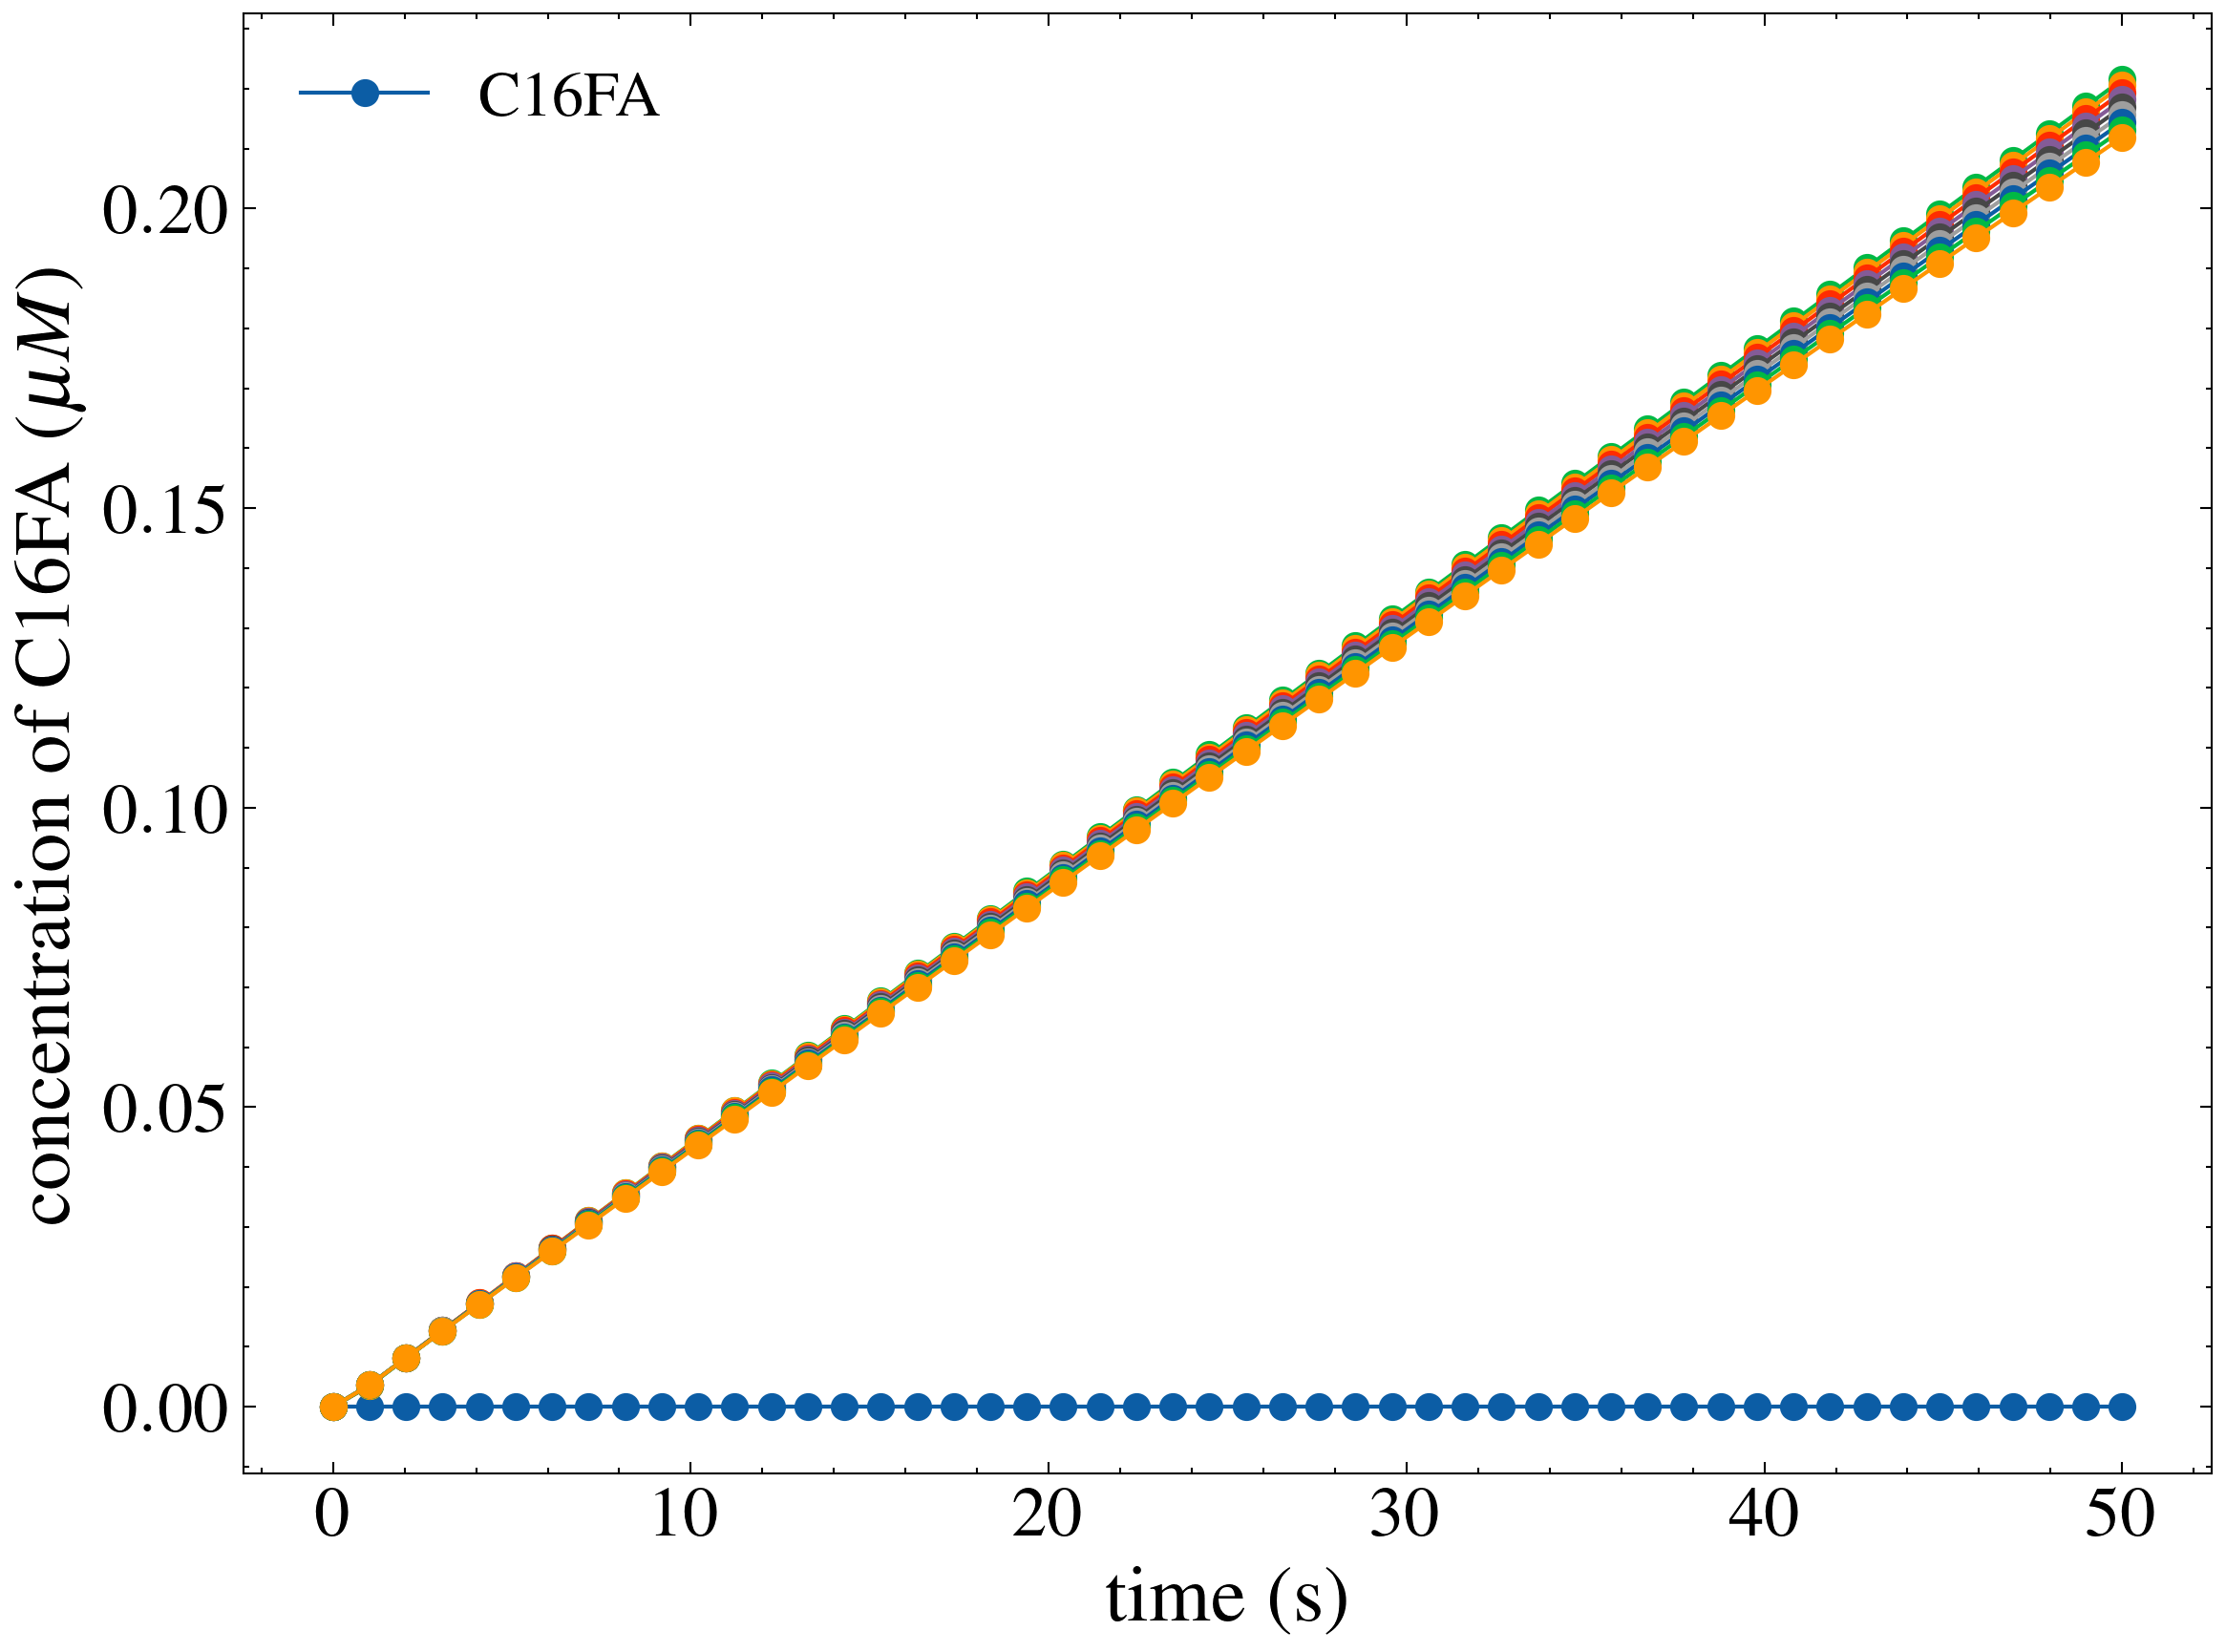

In [51]:
# we make sure here that the rate is linear as we are building rate kinetics 
time_course_production(
    "MalonylCoA",
    "C16FA",
    compounds,
    system,
    y1_dict,
    param,
    0,
    100,
    10,
    max_timea,
    ncp_lista,
)


In [52]:
def produce_data(
    var_substrate: str,
    prod: str,
    compounds: list[str],
    system,
    y0_dict: dict[str, float],
    par: dict[str, float],
    lower_val: float,
    upper_val: float,
    number_of_values: int,
    max_time: float,
    ncp_list: list,
):
    """
    The function   help to build a family of curve of time couse
    by varying a specific substrates

    Returns:
        _type_: _description_
    """
    y0_dict1 = y0_dict.copy()
    list_substrate_values = np.linspace(lower_val, upper_val, number_of_values)
    data_dict = {}
    for i in list_substrate_values:
        y0_dict1[var_substrate] = i
        z0 = np.array(list(y0_dict1.values()))
        time_course_prod = specific_fatty_acid(
            prod, compounds, system, par, z0, max_time, ncp_list
        )
        data_dict[f"{i}"] = time_course_prod
        data_dict["time"] = ncp_list
    return pd.DataFrame(data_dict)

In [54]:
param ={'beta': 0.04345734538274404,
 'kappa': 0.11647817468522687,
 'delta': 1.3021869110230178e-06,
 'kd6': 9.99999997374512,
 'kd7': 0.03,
 'kd8': 0.7000678571704833,
 'kf_CoA': 0.04148645847277749,
 'kb_CoA': 0.00025568688030791487,
 'y0_mal': 22.04}


{'beta': 0.29703,
 'kappa': 0.013594,
 'delta': 1.3021869110230178e-06,
 'kd6': 1.16148,
 'kd7': 0.03,
 'kd8': 0.500782,
 'kf_CoA': 0.2846306917075825,
 'kb_CoA': 0.000257465177385674,
 'y0_mal': 22.04}

{'beta': 0.1,
 'kappa': 0.010380849614980092,
 'delta': 1.2961794629617886e-06,
 'kd6': 0.8893249645810108,
 'kd7': 0.03,
 'kd8': 1,
 'kf_CoA': 0.09560720974651471,
 'kb_CoA': 0.0002567478978547366,
 'y0_mal': 22.04}

{'beta': 0.1,
 'kappa': 0.010380849614980092,
 'delta': 1.2961794629617886e-06,
 'kd6': 0.8893249645810108,
 'kd7': 0.03,
 'kd8': 1,
 'kf_CoA': 0.09560720974651471,
 'kb_CoA': 0.0002567478978547366,
 'y0_mal': 22.04}

In [55]:
def get_km_data(
                substrate, 
                product,
                compounds, 
                system, 
                y1_dict, 
                param, 
                ncp_list, 
                lower_val, 
                upper_val, 
                n_val,
                n_skip=10
                ):
    """
    n_skip: idx of how many initial time points to skip when calculating second derivative
    """
    max_time = ncp_list[-1]
    data = produce_data(
        substrate,
        product,
        compounds,
        system,
        y1_dict,
        param,
        lower_val=lower_val,
        upper_val=upper_val,
        number_of_values=n_val,
        max_time=max_time,
        ncp_list=ncp_list,
    )
    idxs = data.iloc[n_skip:len(data)-2].drop(columns=["time"]).apply(np.gradient, axis=0).apply(np.gradient, axis=0).abs().idxmin()
    rates = {}
    for sub, idx in idxs.items():
        t0 = data.loc[:, "time"].iloc[idx]
        t1 = data.loc[:, "time"].iloc[idx+1]
        c0 = data.loc[:, sub].iloc[idx]
        c1 = data.loc[:, sub].iloc[idx+1]
        rates[float(sub)] = (c1 - c0) / (t1 - t0)
    return pd.Series(rates)

inputs = [  # substrate, product, lower_value, upper_value
    ("MalonylCoA", "C14FA", 0, 22),
    ("MalonylCoA", "C16FA", 2.3, 22),
    ("MalonylCoA", "C18FA", 0, 22),
    ("AcetylCoA", "C14FA", 0, 20),
    ("AcetylCoA", "C16FA", 0, 20),
    ("AcetylCoA", "C18FA", 0, 20),
    ("NADPH", "C14FA", 0, 100),
    ("NADPH", "C16FA", 0, 100),
    ("NADPH", "C18FA", 0, 100),
]


rates_by_stuff = {(sub, prod): get_km_data(
                                    substrate=sub,
                                    product=prod, 
                                    compounds=compounds, 
                                    system=system, 
                                    y1_dict=y1_dict, 
                                    param=param, 
                                    ncp_list = np.linspace(0,100,500), 
                                    lower_val=lower_val, 
                                    upper_val=upper_val, 
                                    n_val=50,
                                    n_skip=75
                                ) 
     for sub, prod, lower_val, upper_val in inputs}



In [56]:
# idxs = data.drop(columns=["time"]).apply(np.gradient, axis=0).apply(np.gradient, axis=0).idxmin()

# for (sub, prod), data in rates_by_stuff.items():    
#     ax = data.plot(xlabel=sub, ylabel=prod)
#     plt.show()

In [57]:
# get rates for fitting

print(rates_by_stuff.keys())

x = rates_by_stuff[('MalonylCoA', 'C14FA')]

sub = x.index.values
rate = x.values

dict_keys([('MalonylCoA', 'C14FA'), ('MalonylCoA', 'C16FA'), ('MalonylCoA', 'C18FA'), ('AcetylCoA', 'C14FA'), ('AcetylCoA', 'C16FA'), ('AcetylCoA', 'C18FA'), ('NADPH', 'C14FA'), ('NADPH', 'C16FA'), ('NADPH', 'C18FA')])


In [58]:
def michaelis_menten(S, par):
    expr = par["vmax"]*S/(par["Km"] + S)
    return expr


def competitve_inhibition(S,I, par):
    expr = par["vmax"]*S/(par["Km"](1+I/par["Ki"]) + S)
    return expr

def michealis_fitting(S, paramet):
    
    expr =  paramet["vmax"]*S/ (paramet["Km"] + S)
    return expr

In [59]:
def cox_hammes_without_inhib(
    acetyl,
    malonyl,
    nadph,
    par
):    
    
    expr = (
        par["kcat"]
        * par["E0"]
        / (
            1
            + (par["km_mal"] / malonyl) * (1 + acetyl / par["ki_acet"])
            + (par["km_acet"] / acetyl) * (1 + malonyl / par["ki_mal"])
            + par["km_nadph"] / nadph
        )
    )
    return expr


In [60]:
def cox_hammes_with_inhib(
    acet,
    mal,
    nadph,
    CoA,
    E0,
    kcat,
    km_acet,
    km_mal,
    km_nadph,
    ki_acet,
    ki_mal,
    ki_CoA
):
    """
    We take into accoun the CoA inhibition 
    """
    expr = (
        kcat
        * E0
        / (
            1
            + (km_mal / mal) * (1 + acet / ki_acet)
            + (km_acet / acet) * (1 + mal / ki_mal +CoA/ki_CoA)
            + km_nadph / nadph
        )
    )
    return expr


# Michaelis Menten parameters of the model with only CoA inhibition with

In [125]:
y1_dict["AcetylCoA"] = 20
y1_dict["MalonylCoA"] = 80
y1_dict["NADPH"] = 160

In [126]:
param ={'beta': 0.04345734538274404,
 'kappa': 0.11647817468522687,
 'delta': 1.3021869110230178e-06,
 'kd6': 9.99999997374512,
 'kd7': 0.03,
 'kd8': 0.7000678571704833,
 'kf_CoA': 0.04148645847277749,
 'kb_CoA': 0.00025568688030791487,
 'y0_mal': 22.04}


{'beta': 0.29703,
 'kappa': 0.013594,
 'delta': 1.3021869110230178e-06,
 'kd6': 1.16148,
 'kd7': 0.03,
 'kd8': 0.500782,
 'kf_CoA': 0.2846306917075825,
 'kb_CoA': 0.000257465177385674,
 'y0_mal': 22.04}


{'beta': 0.2730953249345043,
 'kappa': 0.11593298460744961,
 'delta': 1.3021951378311414e-06,
 'kd6': 9.952540270827324,
 'kd7': 0.03,
 'kd8': 0.6998025977314731,
 'kf_CoA': 0.26196010767212086,
 'kb_CoA': 0.00025816623581081943,
 'y0_mal': 22.04}


{'beta': 0.04348285079898573,
 'kappa': 0.11593298460744961,
 'delta': 1.3021951378311414e-06,
 'kd6': 9.952540270827324,
 'kd7': 0.03,
 'kd8': 0.6998025977314731,
 'y0_mal': 22.04}

{'beta': 0.1,
 'kappa': 0.010380849614980092,
 'delta': 1.2961794629617886e-06,
 'kd6': 0.8893249645810108,
 'kd7': 0.03,
 'kd8': 1,
 'kf_CoA': 0.09560720974651471,
 'kb_CoA': 0.0002567478978547366,
 'y0_mal': 22.04}



{'beta': 0.1,
 'kappa': 0.010380849614980092,
 'delta': 1.2961794629617886e-06,
 'kd6': 0.8893249645810108,
 'kd7': 0.03,
 'kd8': 1,
 'kf_CoA': 0.09560720974651471,
 'kb_CoA': 0.0002567478978547366,
 'y0_mal': 22.04}

In [127]:
rc={'axes.labelsize': 12, 'font.size': 11, 'legend.fontsize': 11.0, 'axes.titlesize':12}
plt.rcParams.update(**rc)
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 

In [128]:
def resid(parameters, S, data):
    # y0[1] = parameters["y0_mal"].value
    # print(y0)
    model = michealis_fitting(S=S, paramet=parameters)
    
    res = (model - data).ravel()

    return res

### Fitting acetyl-CoA 

In [146]:
y1_dict["AcetylCoA"] = 14.3
y1_dict["MalonylCoA"] = 10
y1_dict["NADPH"] = 100
y1_dict["E"] = 0.02

In [147]:
inputs = [  # substrate, product, lower_value, upper_value
    ("AcetylCoA", "C14FA", 1.3, 147),
    ("AcetylCoA", "C16FA", 1.3, 147),
    ("AcetylCoA", "C18FA", 1.3, 147),
    
]


rates_by_stuff_acetyl = {(sub, prod): get_km_data(
                                    substrate=sub,
                                    product=prod, 
                                    compounds=compounds, 
                                    system=system, 
                                    y1_dict=y1_dict, 
                                    param=param, 
                                    ncp_list = np.linspace(0,50,500), 
                                    lower_val=lower_val, 
                                    upper_val=upper_val, 
                                    n_val=40,
                                    n_skip=50
                                ) 
     for sub, prod, lower_val, upper_val in inputs}


In [148]:
concentration_enzyme =0.02

In [149]:
acetyl_fitting_C14 = rates_by_stuff_acetyl[('AcetylCoA', 'C14FA')]

acet_C14 = acetyl_fitting_C14.index.values
data_acet_C14 = acetyl_fitting_C14.values


paramet_acetyl_C14 =Parameters()
paramet_acetyl_C14.add("vmax", value=1, min =0)
paramet_acetyl_C14.add("Km", value=10, min =0)

result_acet_C14 = minimize(
        resid,
        params=paramet_acetyl_C14, 
        args=(
        
            acet_C14,
        data_acet_C14,
        ),
        method="leastsq",
    )

par_acet_C14= dict(result_acet_C14.params.valuesdict())
kcat_C14 = par_acet_C14["vmax"]/concentration_enzyme 
par_acet_C14["kcat"] =kcat_C14

print("Parameter of C14: ", par_acet_C14 )
#######################################################################

#########################################################################



acetyl_fitting_C16 = rates_by_stuff_acetyl[('AcetylCoA', 'C16FA')]

acet_C16 = acetyl_fitting_C16.index.values
data_acet_C16 = acetyl_fitting_C16.values

paramet_acetyl_C16 =Parameters()
paramet_acetyl_C16.add("vmax", value=1, min =0)
paramet_acetyl_C16.add("Km", value=1, min =0)

result_acet_C16 = minimize(
        resid,
        params=paramet_acetyl_C16, 
        args=(
        
            acet_C16,
        data_acet_C16,
        ),
        method="leastsq",
    )



par_acet_C16= dict(result_acet_C16.params.valuesdict())
kcat_C16 = par_acet_C16["vmax"]/concentration_enzyme 
par_acet_C16["kcat"] =kcat_C16

print("Parameter of C16: ", par_acet_C16 )


##############################################################

#################################################################


acetyl_fitting_C18 = rates_by_stuff_acetyl[('AcetylCoA', 'C18FA')]

acet_C18 = acetyl_fitting_C18.index.values
data_acet_C18 = acetyl_fitting_C18.values

paramet_acetyl_C18 =Parameters()
paramet_acetyl_C18.add("vmax", value=1, min =0)
paramet_acetyl_C18.add("Km", value=1, min =0)

result_acet_C18 = minimize(
        resid,
        params=paramet_acetyl_C18, 
        args=(
        
            acet_C18,
        data_acet_C18,
        ),
        method="leastsq",
    )



par_acet_C18= dict(result_acet_C18.params.valuesdict())
kcat_C18 = par_acet_C18["vmax"]/concentration_enzyme 
par_acet_C18["kcat"] =kcat_C18
print("Parameter of C18: ", par_acet_C18 )





Parameter of C14:  {'vmax': 5.548154401813221e-05, 'Km': 1.3573209044012096, 'kcat': 0.0027740772009066106}
Parameter of C16:  {'vmax': 0.0005987310830912751, 'Km': 0.9889719052906405, 'kcat': 0.029936554154563755}
Parameter of C18:  {'vmax': 2.536815567277806e-05, 'Km': 0.983247937963057, 'kcat': 0.001268407783638903}


### Plot

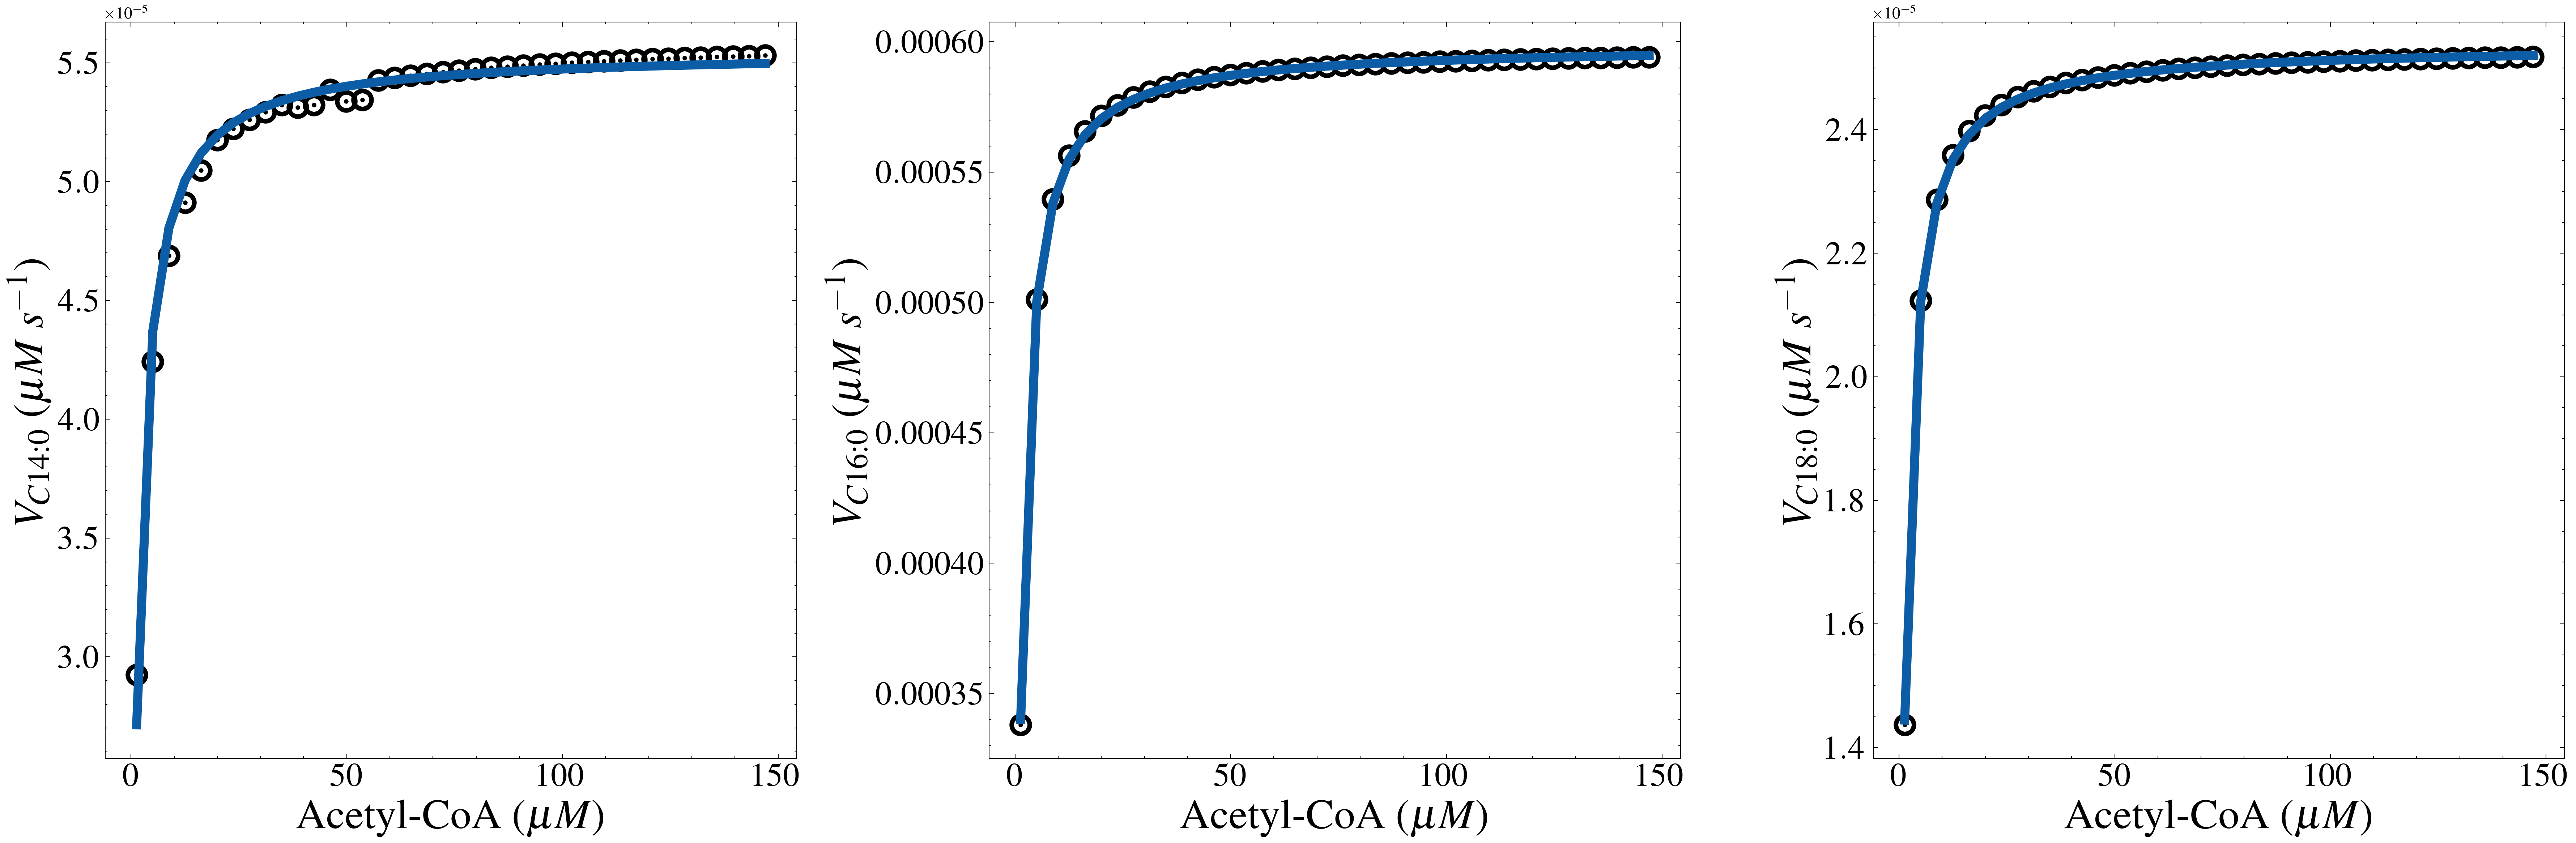

In [150]:
fig, (ax1, ax2,ax3) = plt.subplots(1, 3, figsize=(24, 8))
ax1.scatter(acet_C14, data_acet_C14, marker=".",color ="k", linewidths=12)
ax1.plot(acet_C14, michaelis_menten(acet_C14, par_acet_C14),linewidth =6)

ax2.scatter(acet_C16, data_acet_C16, marker=".",color ="k", linewidths=12)
ax2.plot(acet_C16, michaelis_menten(acet_C16, par_acet_C16),linewidth =6)

ax3.scatter(acet_C18, data_acet_C18, marker=".",color ="k", linewidths=12)
ax3.plot(acet_C18, michaelis_menten(acet_C18, par_acet_C18),linewidth =6)

ax1.tick_params(axis="both",  labelsize=22)
ax2.tick_params(axis="both", labelsize=22)
ax3.tick_params(axis="both", labelsize=22)
ax1.set_xlabel(r"Acetyl-CoA ($\mu M$)", fontsize=28)
ax2.set_xlabel(r"Acetyl-CoA ($\mu M$)", fontsize=28)
ax3.set_xlabel(r"Acetyl-CoA ($\mu M$)", fontsize=28)
ax1.set_ylabel(r"$V_{C14:0}$ ($\mu M$ $s^{-1}$) ",fontsize=28)
ax2.set_ylabel(r"$V_{C16:0}$ ($\mu M$ $s^{-1}$) ",fontsize=28)
ax3.set_ylabel(r"$V_{C18:0}$ ($\mu M$ $s^{-1}$) ",fontsize=28)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "rate_acetyl_CoA.eps", bbox_inches="tight")

In [133]:
inputs = [  # substrate, product, lower_value, upper_value
    ("MalonylCoA", "C14FA", 0, 23),
    ("MalonylCoA", "C16FA", 0, 23),
    ("MalonylCoA", "C18FA", 0, 23),
    ("AcetylCoA", "C14FA", 0, 108),
    ("AcetylCoA", "C16FA", 0, 108),
    ("AcetylCoA", "C18FA", 0, 108),
    ("NADPH", "C14FA", 0, 200),
    ("NADPH", "C16FA", 0, 200),
    ("NADPH", "C18FA", 0, 200),
]


rates_by_stuff = {(sub, prod): get_km_data(
                                    substrate=sub,
                                    product=prod, 
                                    compounds=compounds, 
                                    system=system, 
                                    y1_dict=y1_dict, 
                                    param=param, 
                                    ncp_list = np.linspace(0,120,100), 
                                    lower_val=lower_val, 
                                    upper_val=upper_val, 
                                    n_val=30,
                                    n_skip=75
                                ) 
     for sub, prod, lower_val, upper_val in inputs}


# Fitting Malonyl-CoA

In [ ]:
y1_dict["AcetylCoA"] = 14.3
y1_dict["MalonylCoA"] = 10
y1_dict["NADPH"] = 100
y1_dict["E"] = 0.02

In [186]:
inputs_malonyl = [  # substrate, product, lower_value, upper_value
    ("MalonylCoA", "C14FA", 1.3,10),
    ("MalonylCoA", "C16FA", 1.3,10),
    ("MalonylCoA", "C18FA", 1.3,10),
    
]


rates_by_stuff_malonyl = {(sub, prod): get_km_data(
                                    substrate=sub,
                                    product=prod, 
                                    compounds=compounds, 
                                    system=system, 
                                    y1_dict=y1_dict, 
                                    param=param, 
                                    ncp_list = np.linspace(0,20,100), 
                                    lower_val=lower_val, 
                                    upper_val=upper_val, 
                                    n_val=40,
                                    n_skip=20
                                ) 
     for sub, prod, lower_val, upper_val in inputs_malonyl}


In [187]:
malonyl_fitting_C14 = rates_by_stuff_malonyl[('MalonylCoA', 'C14FA')]

mal_C14 = malonyl_fitting_C14.index.values
data_mal_C14 = malonyl_fitting_C14.values


paramet_malonyl_C14 =Parameters()
paramet_malonyl_C14.add("vmax", value=0.1, min =0.0001, max =10)
paramet_malonyl_C14.add("Km", value=0.1, min =0.001, max= 10)

result_mal_C14 = minimize(
        resid,
        params=paramet_malonyl_C14, 
        args=(
        
            mal_C14,
        data_mal_C14,
        ),
        method="leastsq",
    )

par_mal_C14= dict(result_mal_C14.params.valuesdict())
kcat_C14 = par_mal_C14["vmax"]/concentration_enzyme 
par_mal_C14["kcat"] =kcat_C14

print("Parameter of C14: ", par_mal_C14 )
#######################################################################

#########################################################################



malonyl_fitting_C16 = rates_by_stuff_malonyl[('MalonylCoA', 'C16FA')]

mal_C16 = malonyl_fitting_C16.index.values
data_mal_C16 = malonyl_fitting_C16.values

paramet_malonyl_C16 =Parameters()
paramet_malonyl_C16.add("vmax", value=0.1, min =0, max=10)
paramet_malonyl_C16.add("Km", value=20, min =0, max =10)

result_mal_C16 = minimize(
        resid,
        params=paramet_malonyl_C16, 
        args=(
        
            mal_C16,
        data_mal_C16,
        ),
        method="leastsq",
    )



par_mal_C16= dict(result_mal_C16.params.valuesdict())
kcat_C16 = par_mal_C16["vmax"]/concentration_enzyme 
par_mal_C16["kcat"] =kcat_C16

print("Parameter of C16: ", par_mal_C16 )


##############################################################

#################################################################


malonyl_fitting_C18 = rates_by_stuff_malonyl[('MalonylCoA', 'C18FA')]

mal_C18 = malonyl_fitting_C18.index.values
data_mal_C18 = malonyl_fitting_C18.values

paramet_malonyl_C18 =Parameters()
paramet_malonyl_C18.add("vmax", value=0.1, min =0)
paramet_malonyl_C18.add("Km", value=1, min =0, )

result_mal_C18 = minimize(
        resid,
        params=paramet_malonyl_C18, 
        args=(
        
            mal_C18,
        data_mal_C18,
        ),
        method="leastsq",
    )



par_mal_C18= dict(result_mal_C18.params.valuesdict())
kcat_C18 = par_mal_C18["vmax"]/concentration_enzyme 
par_mal_C18["kcat"] =kcat_C18
print("Parameter of C18: ", par_mal_C18 )





Parameter of C14:  {'vmax': 0.0001324877375069129, 'Km': 0.001000000003954774, 'kcat': 0.006624386875345644}
Parameter of C16:  {'vmax': 0.0005925308301113485, 'Km': 0.04930772555743146, 'kcat': 0.029626541505567427}
Parameter of C18:  {'vmax': 1024.4417504127882, 'Km': 415532061.7205576, 'kcat': 51222.08752063941}


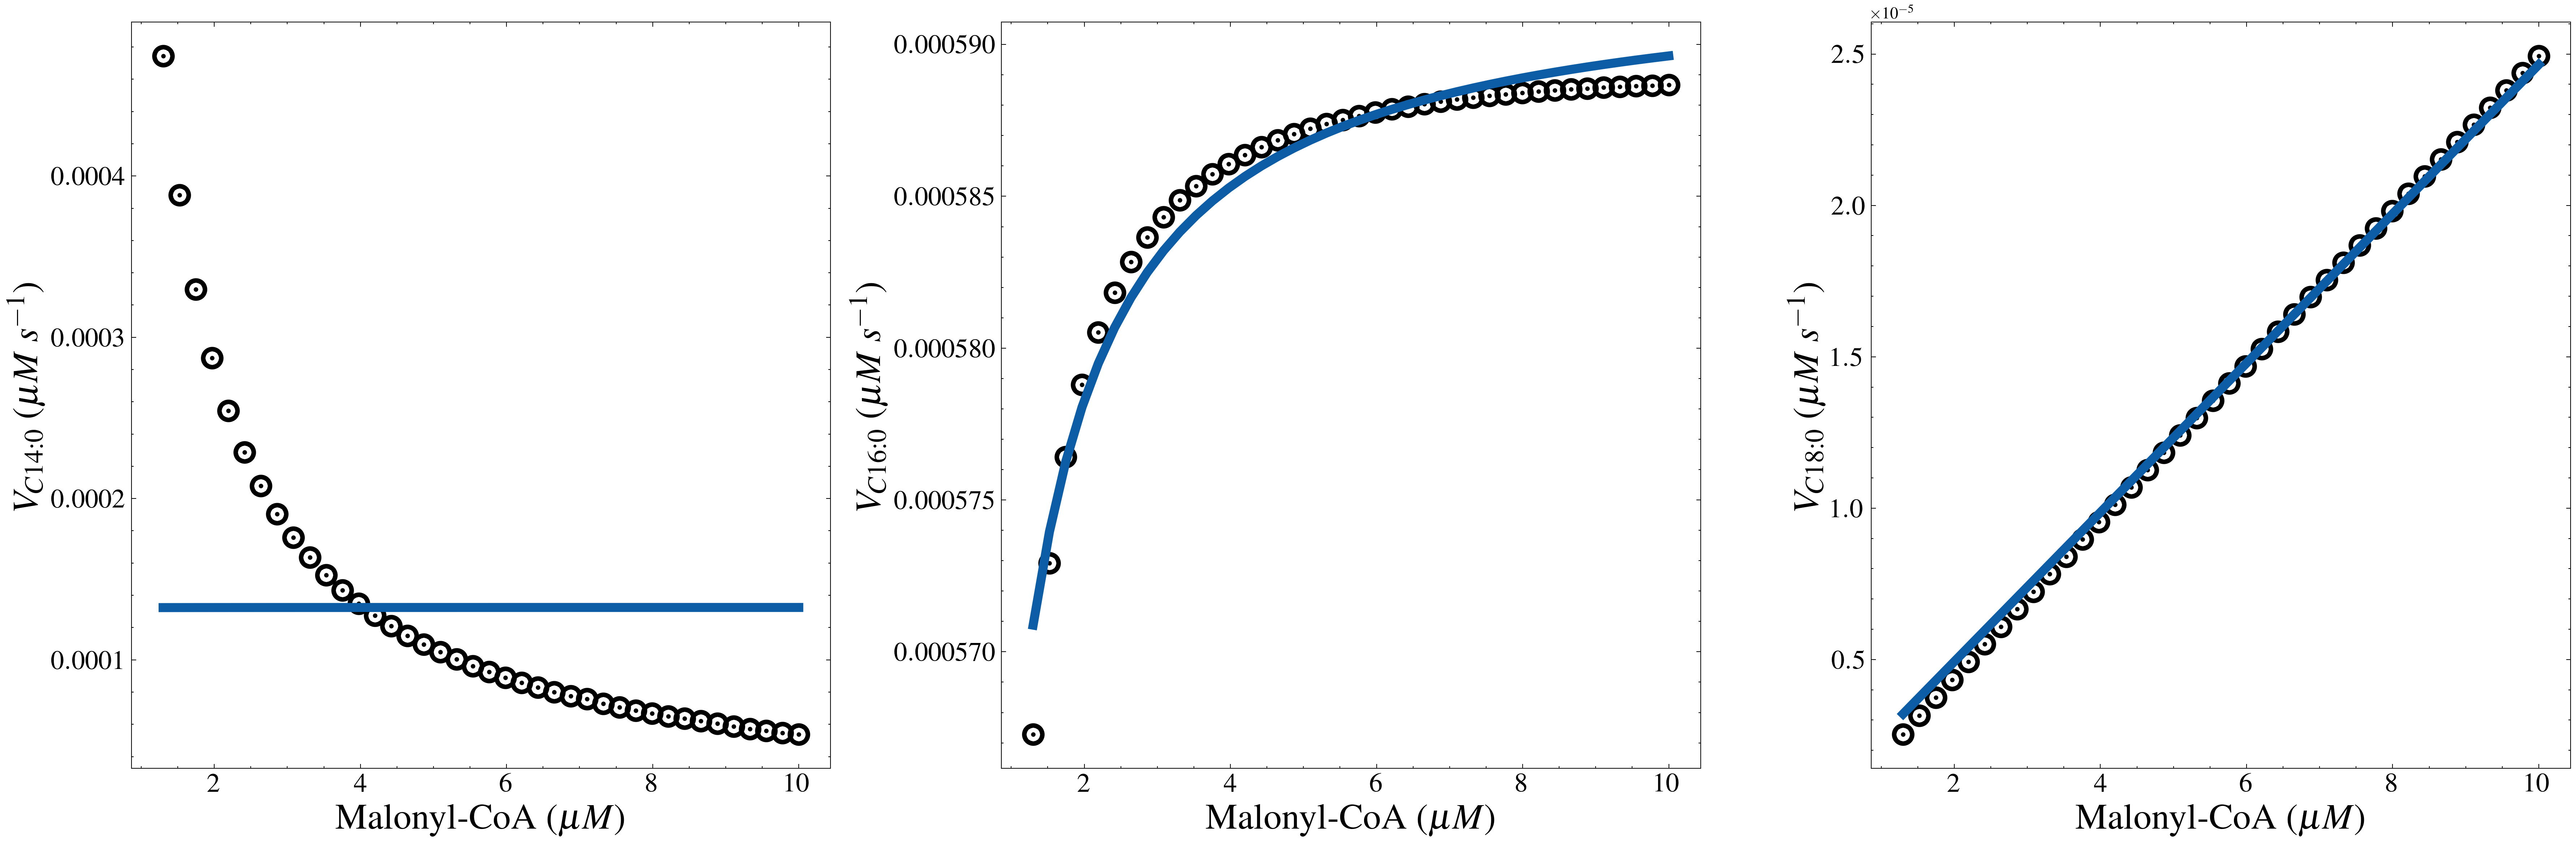

In [188]:
fig, (ax1, ax2,ax3) = plt.subplots(1, 3, figsize=(24, 8))
ax1.scatter(mal_C14, data_mal_C14, marker=".",color ="k", linewidths=12)
ax1.plot(mal_C14, michaelis_menten(mal_C14, par_mal_C14),linewidth=6)

ax2.scatter(mal_C16, data_mal_C16, marker=".",color ="k", linewidths=12)
ax2.plot(mal_C16, michaelis_menten(mal_C16, par_mal_C16),linewidth=6)

ax3.scatter(mal_C18, data_mal_C18, marker=".",color ="k", linewidths=12)
ax3.plot(mal_C18, michaelis_menten(mal_C18, par_mal_C18),linewidth=6)


ax1.tick_params(axis="both",  labelsize=18)
ax2.tick_params(axis="both", labelsize=18)
ax3.tick_params(axis="both", labelsize=18)
ax1.set_xlabel(r"Malonyl-CoA ($\mu M$)", fontsize=24)
ax2.set_xlabel(r"Malonyl-CoA ($\mu M$)", fontsize=24)
ax3.set_xlabel(r"Malonyl-CoA ($\mu M$)", fontsize=24)
ax1.set_ylabel(r"$V_{C14:0}$ ($\mu M$ $s^{-1}$) ",fontsize=24)
ax2.set_ylabel(r"$V_{C16:0}$ ($\mu M$ $s^{-1}$) ",fontsize=24)
ax3.set_ylabel(r"$V_{C18:0}$ ($\mu M$ $s^{-1}$) ",fontsize=24)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "rate_Malonyl-Co12.eps", bbox_inches="tight")

# Fitting NADPH

In [178]:
y1_dict["AcetylCoA"] =57
y1_dict["MalonylCoA"] =10
y1_dict["NADPH"] = 100
y1_dict["E"] = 0.02

In [179]:
inputs_nadph = [  # substrate, product, lower_value, upper_value
    ("NADPH", "C14FA", 1.3, 150),
    ("NADPH", "C16FA", 1.3, 150),
    ("NADPH", "C18FA", 1.3, 150),
    
]


rates_by_stuff_nadph = {(sub, prod): get_km_data(
                                    substrate=sub,
                                    product=prod, 
                                    compounds=compounds, 
                                    system=system, 
                                    y1_dict=y1_dict, 
                                    param=param, 
                                    ncp_list = np.linspace(0,20,100), 
                                    lower_val=lower_val, 
                                    upper_val=upper_val, 
                                    n_val=30,
                                    n_skip=10
                                ) 
     for sub, prod, lower_val, upper_val in inputs_nadph}


In [180]:
nadph_fitting_C14 = rates_by_stuff_nadph[('NADPH', 'C14FA')]

nadph_C14 = nadph_fitting_C14.index.values
data_nadph_C14 = nadph_fitting_C14.values


paramet_nadph_C14 =Parameters()
paramet_nadph_C14.add("vmax", value=0.1, min =0)
paramet_nadph_C14.add("Km", value=10, min =0)

result_nadph_C14 = minimize(
        resid,
        params=paramet_nadph_C14, 
        args=(
        
           nadph_C14,
        data_nadph_C14,
        ),
        method="leastsq",
    )

par_nadph_C14= dict(result_nadph_C14.params.valuesdict())
kcat_C14 = par_nadph_C14["vmax"]/concentration_enzyme 
par_nadph_C14["kcat"] =kcat_C14

print("Parameter of C14: ", par_nadph_C14 )
#######################################################################

#########################################################################



nadph_fitting_C16 = rates_by_stuff_nadph[('NADPH', 'C16FA')]

nadph_C16 = nadph_fitting_C16.index.values
data_nadph_C16 = nadph_fitting_C16.values

paramet_nadph_C16 =Parameters()
paramet_nadph_C16.add("vmax", value=0.1, min =0)
paramet_nadph_C16.add("Km", value=20, min =0)

result_nadph_C16 = minimize(
        resid,
        params=paramet_nadph_C16, 
        args=(
        
            nadph_C16,
        data_nadph_C16,
        ),
        method="leastsq",
    )



par_nadph_C16= dict(result_nadph_C16.params.valuesdict())
kcat_C16 = par_nadph_C16["vmax"]/concentration_enzyme 
par_nadph_C16["kcat"] =kcat_C16

print("Parameter of C16: ", par_nadph_C16 )


##############################################################

#################################################################


nadph_fitting_C18 = rates_by_stuff_nadph[('NADPH', 'C18FA')]

nadph_C18 = nadph_fitting_C18.index.values
data_nadph_C18 = nadph_fitting_C18.values

paramet_nadph_C18 =Parameters()
paramet_nadph_C18.add("vmax", value=10, min =0)
paramet_nadph_C18.add("Km", value=1, min =0)

result_nadph_C18 = minimize(
        resid,
        params=paramet_nadph_C18, 
        args=(
        
            nadph_C18,
        data_nadph_C18,
        ),
        method="leastsq",
    )



par_nadph_C18= dict(result_nadph_C18.params.valuesdict())
kcat_C18 = par_nadph_C18["vmax"]/concentration_enzyme 
par_nadph_C18["kcat"] =kcat_C18
print("Parameter of C18: ", par_nadph_C18 )





Parameter of C14:  {'vmax': 0.00018135816103281854, 'Km': 1.4907270973196773e-09, 'kcat': 0.009067908051640927}
Parameter of C16:  {'vmax': 0.0006113026815217637, 'Km': 2.225626943000153, 'kcat': 0.030565134076088185}
Parameter of C18:  {'vmax': 5988.234733855296, 'Km': 24020052006.79268, 'kcat': 299411.7366927648}


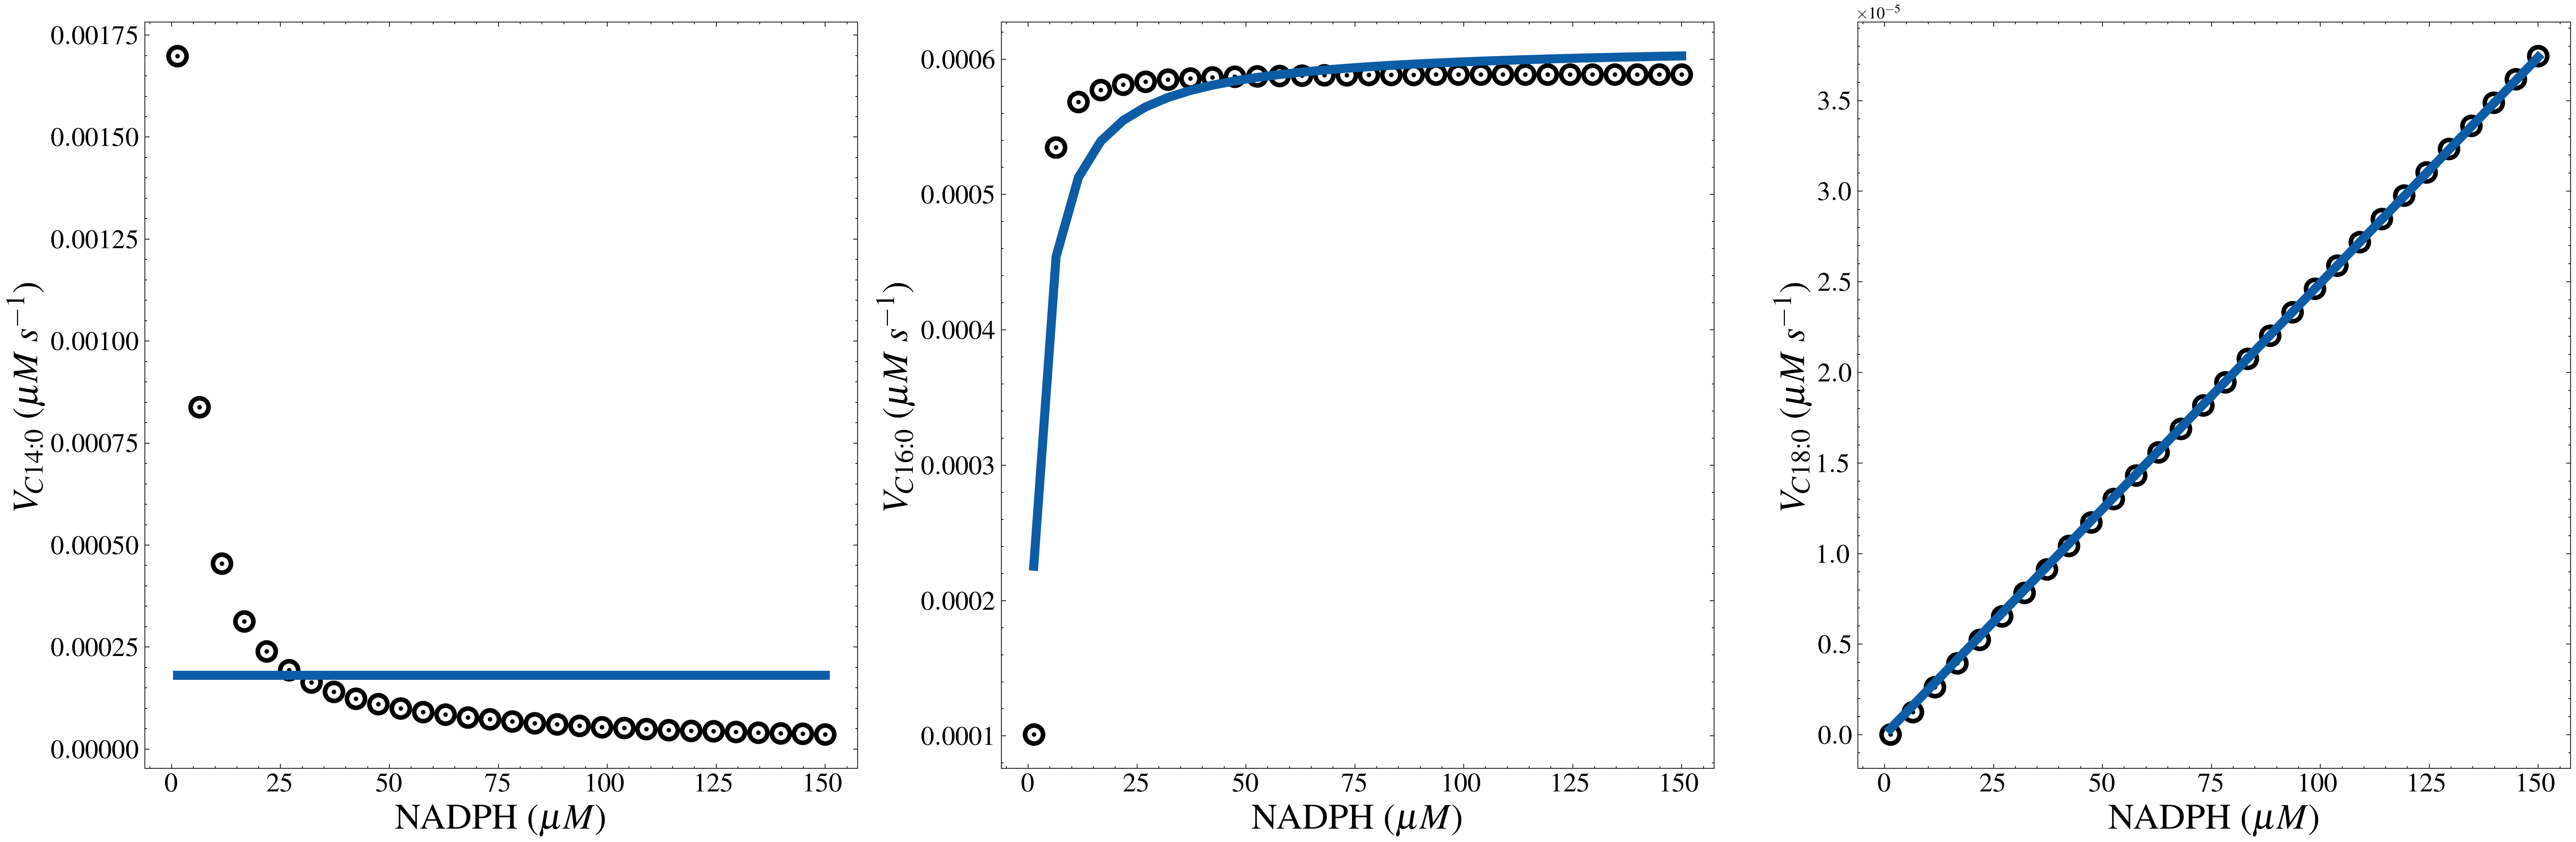

In [181]:
fig, (ax1, ax2,ax3) = plt.subplots(1, 3, figsize=(24, 8))




ax1.scatter(nadph_C14, data_nadph_C14, marker=".",color ="k", linewidths=12)
ax1.plot(nadph_C14, michaelis_menten(nadph_C14, par_nadph_C14),linewidth =6)

ax2.scatter(nadph_C16, data_nadph_C16, marker=".",color ="k", linewidths=12)
ax2.plot(nadph_C16, michaelis_menten(nadph_C16, par_nadph_C16),linewidth =6)

ax3.scatter(nadph_C18, data_nadph_C18, marker=".",color ="k", linewidths=12)
ax3.plot(nadph_C18, michaelis_menten(nadph_C18, par_nadph_C18),linewidth =6)

ax1.tick_params(axis="both",  labelsize=18)
ax2.tick_params(axis="both", labelsize=18)
ax3.tick_params(axis="both", labelsize=18)
ax1.set_xlabel(r"NADPH ($\mu M$)", fontsize=24)
ax2.set_xlabel(r"NADPH ($\mu M$)", fontsize=24)
ax3.set_xlabel(r"NADPH ($\mu M$)", fontsize=24)
ax1.set_ylabel(r"$V_{C14:0}$ ($\mu M$ $s^{-1}$) ",fontsize=24)
ax2.set_ylabel(r"$V_{C16:0}$ ($\mu M$ $s^{-1}$) ",fontsize=24)
ax3.set_ylabel(r"$V_{C18:0}$ ($\mu M$ $s^{-1}$) ",fontsize=24)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "rate_nadph_CoA.eps", bbox_inches="tight")

In [182]:
mal, data_mal = steady_state_kinetics(
    "MalonylCoA",
    "C16FA",
    compounds,
    system,
    y1_dict,
    param,
    0,
    10,
    30,
    max_timea,
    ncp_lista,
)

In [173]:
result_mal = minimize(
        resid,
        params=paramet, 
        args=(
        
            mal,
        data_mal,
        ),
        method="leastsq",
    )



par_mal = dict(result_mal.params.valuesdict())
par_mal

NameError: name 'paramet' is not defined

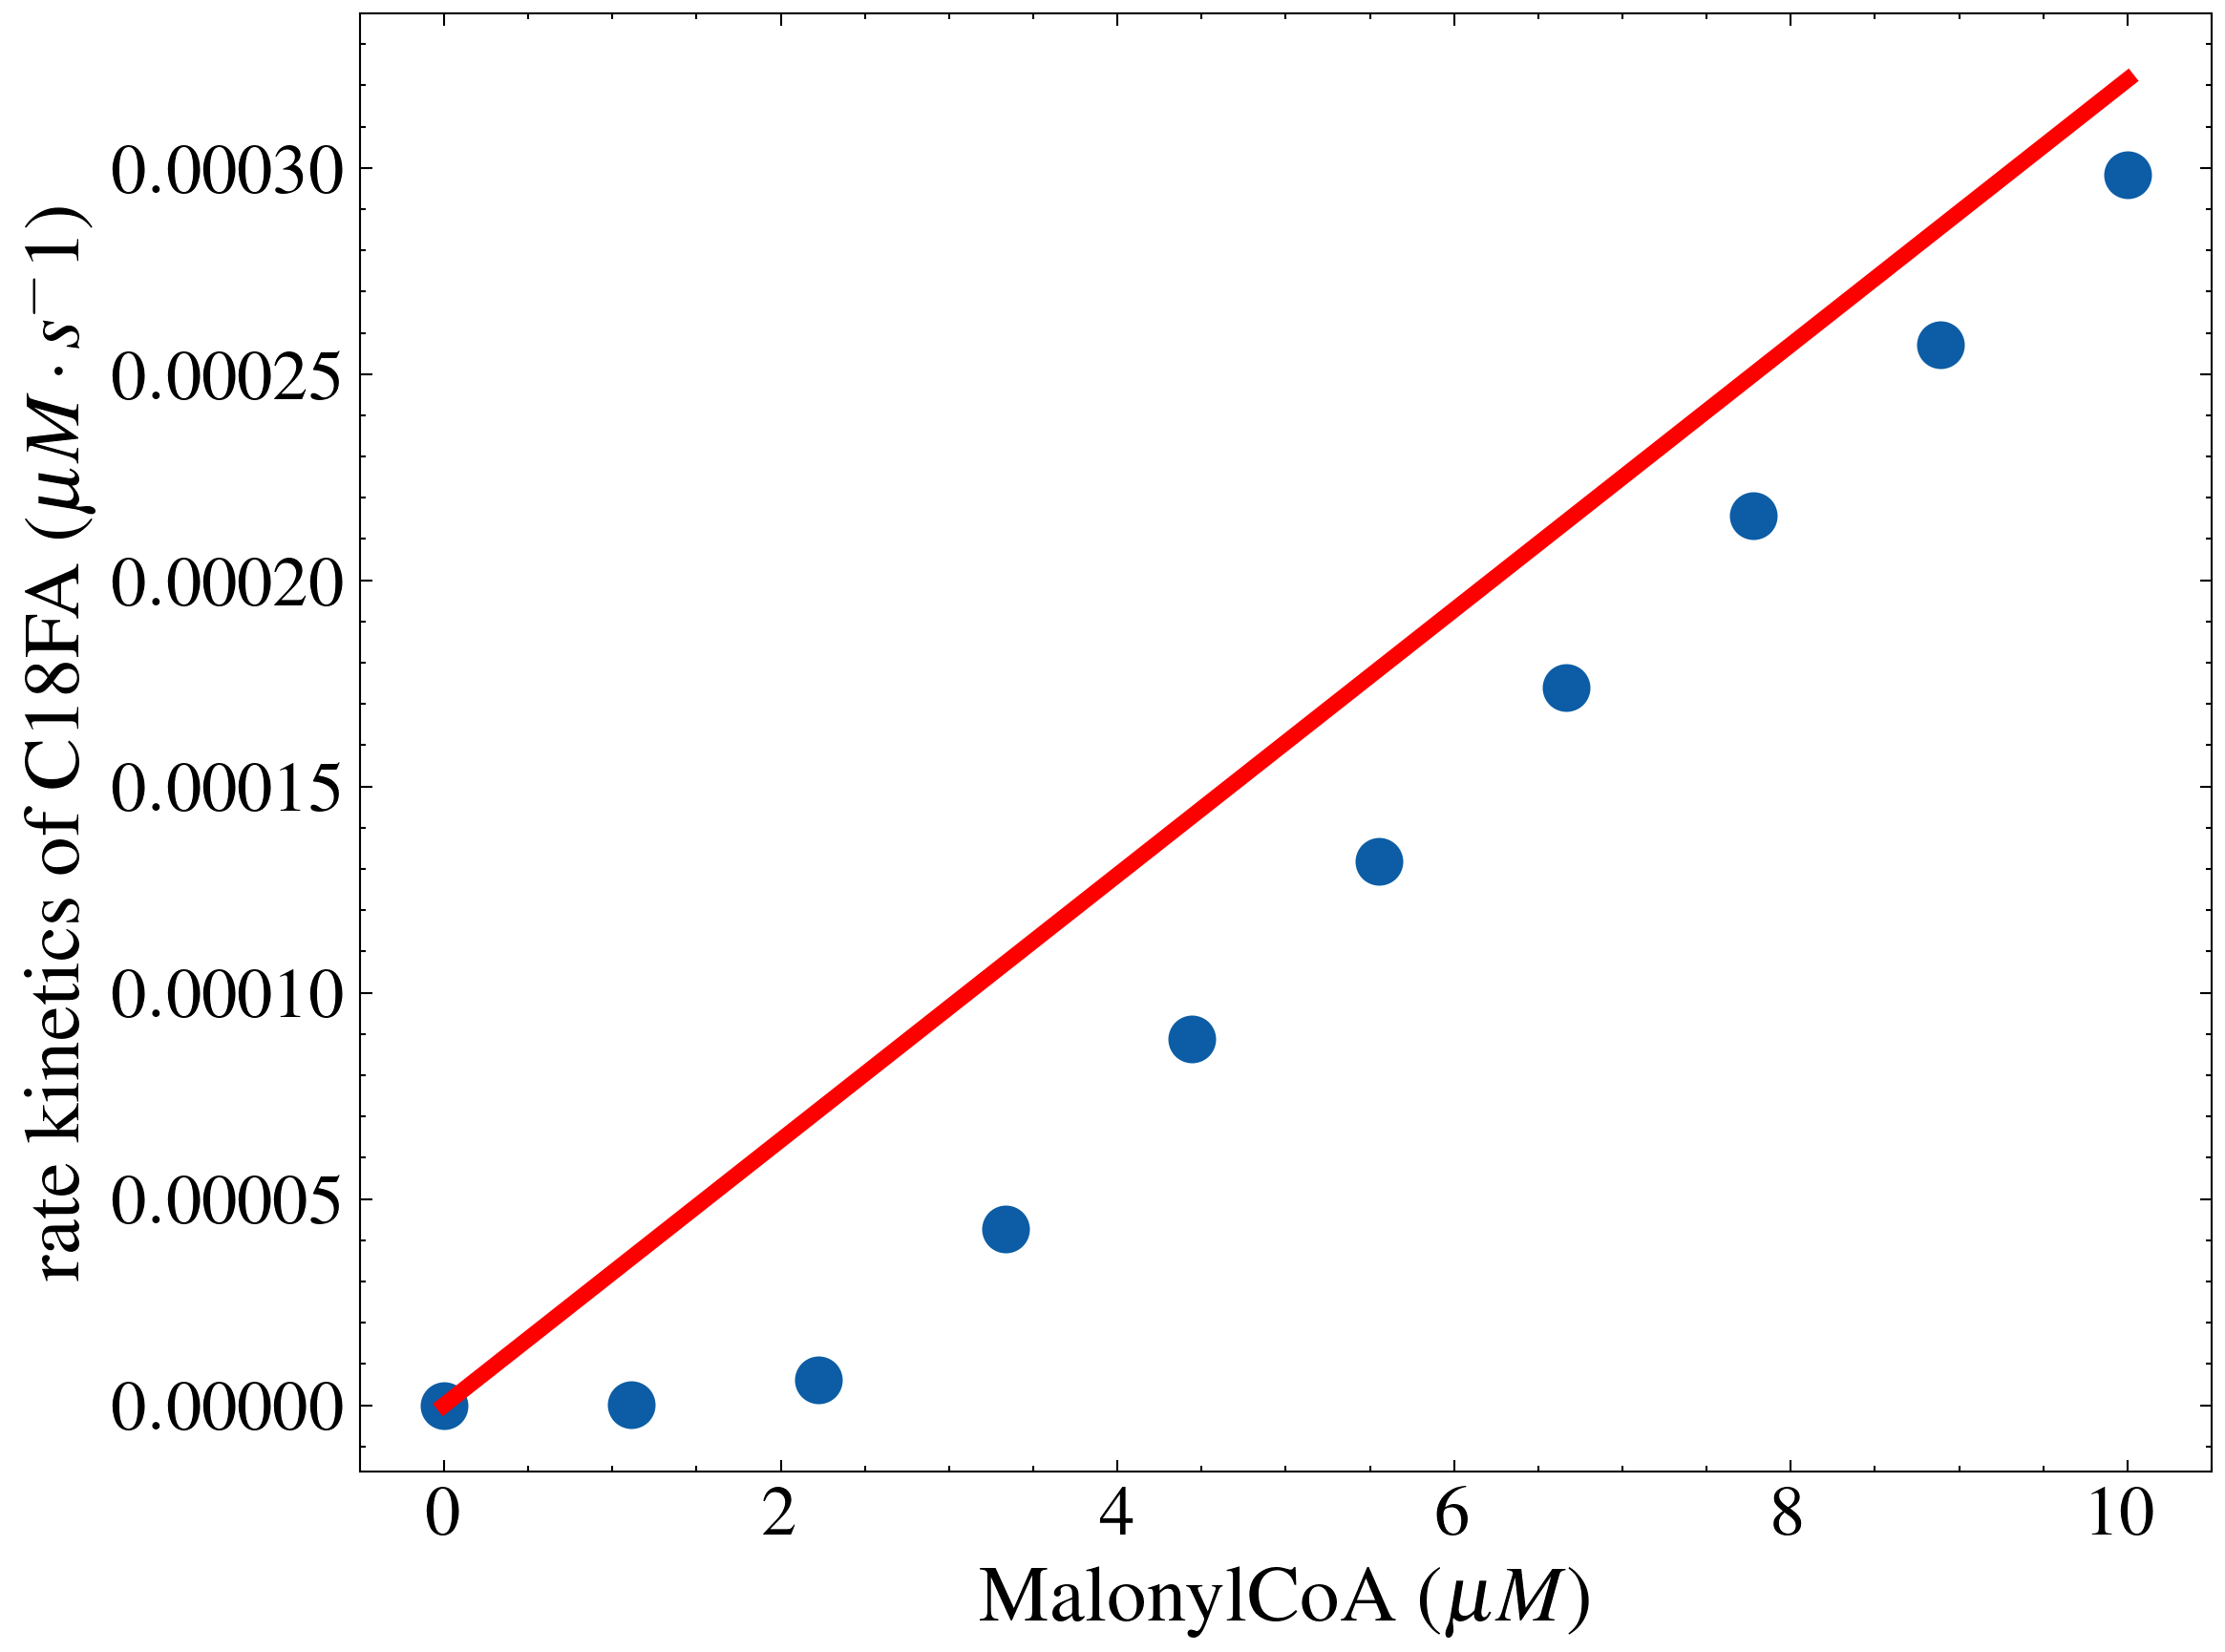

In [ ]:
plot_mal =steady_state_kinetic_plot(
    "MalonylCoA",
    "C18FA",
    compounds,
    system,
    y1_dict,
    param,
    0,
    10,
    10,
    max_timea,
    ncp_lista,
)


plt.plot(mal, michealis_fitting(mal, par_mal_C18),color ="r", linewidth =4)
plt.savefig(RESULTS_DIR /"mal_c16.eps", bbox_inches="tight")
plt.show()

In [ ]:
nadph, data_nadph = steady_state_kinetics(
    "NADPH",
    "C16FA",
    compounds,
    system,
    y1_dict,
    param,
    0,
    100,
    30,
    max_timea,
    ncp_lista,
)

In [ ]:
result_nadph = minimize(
        resid,
        params=paramet, 
        args=(
        
            nadph,
        data_nadph,
        ),
        method="leastsq",
    )



result_mal

par_nadph = dict(result_nadph.params.valuesdict())

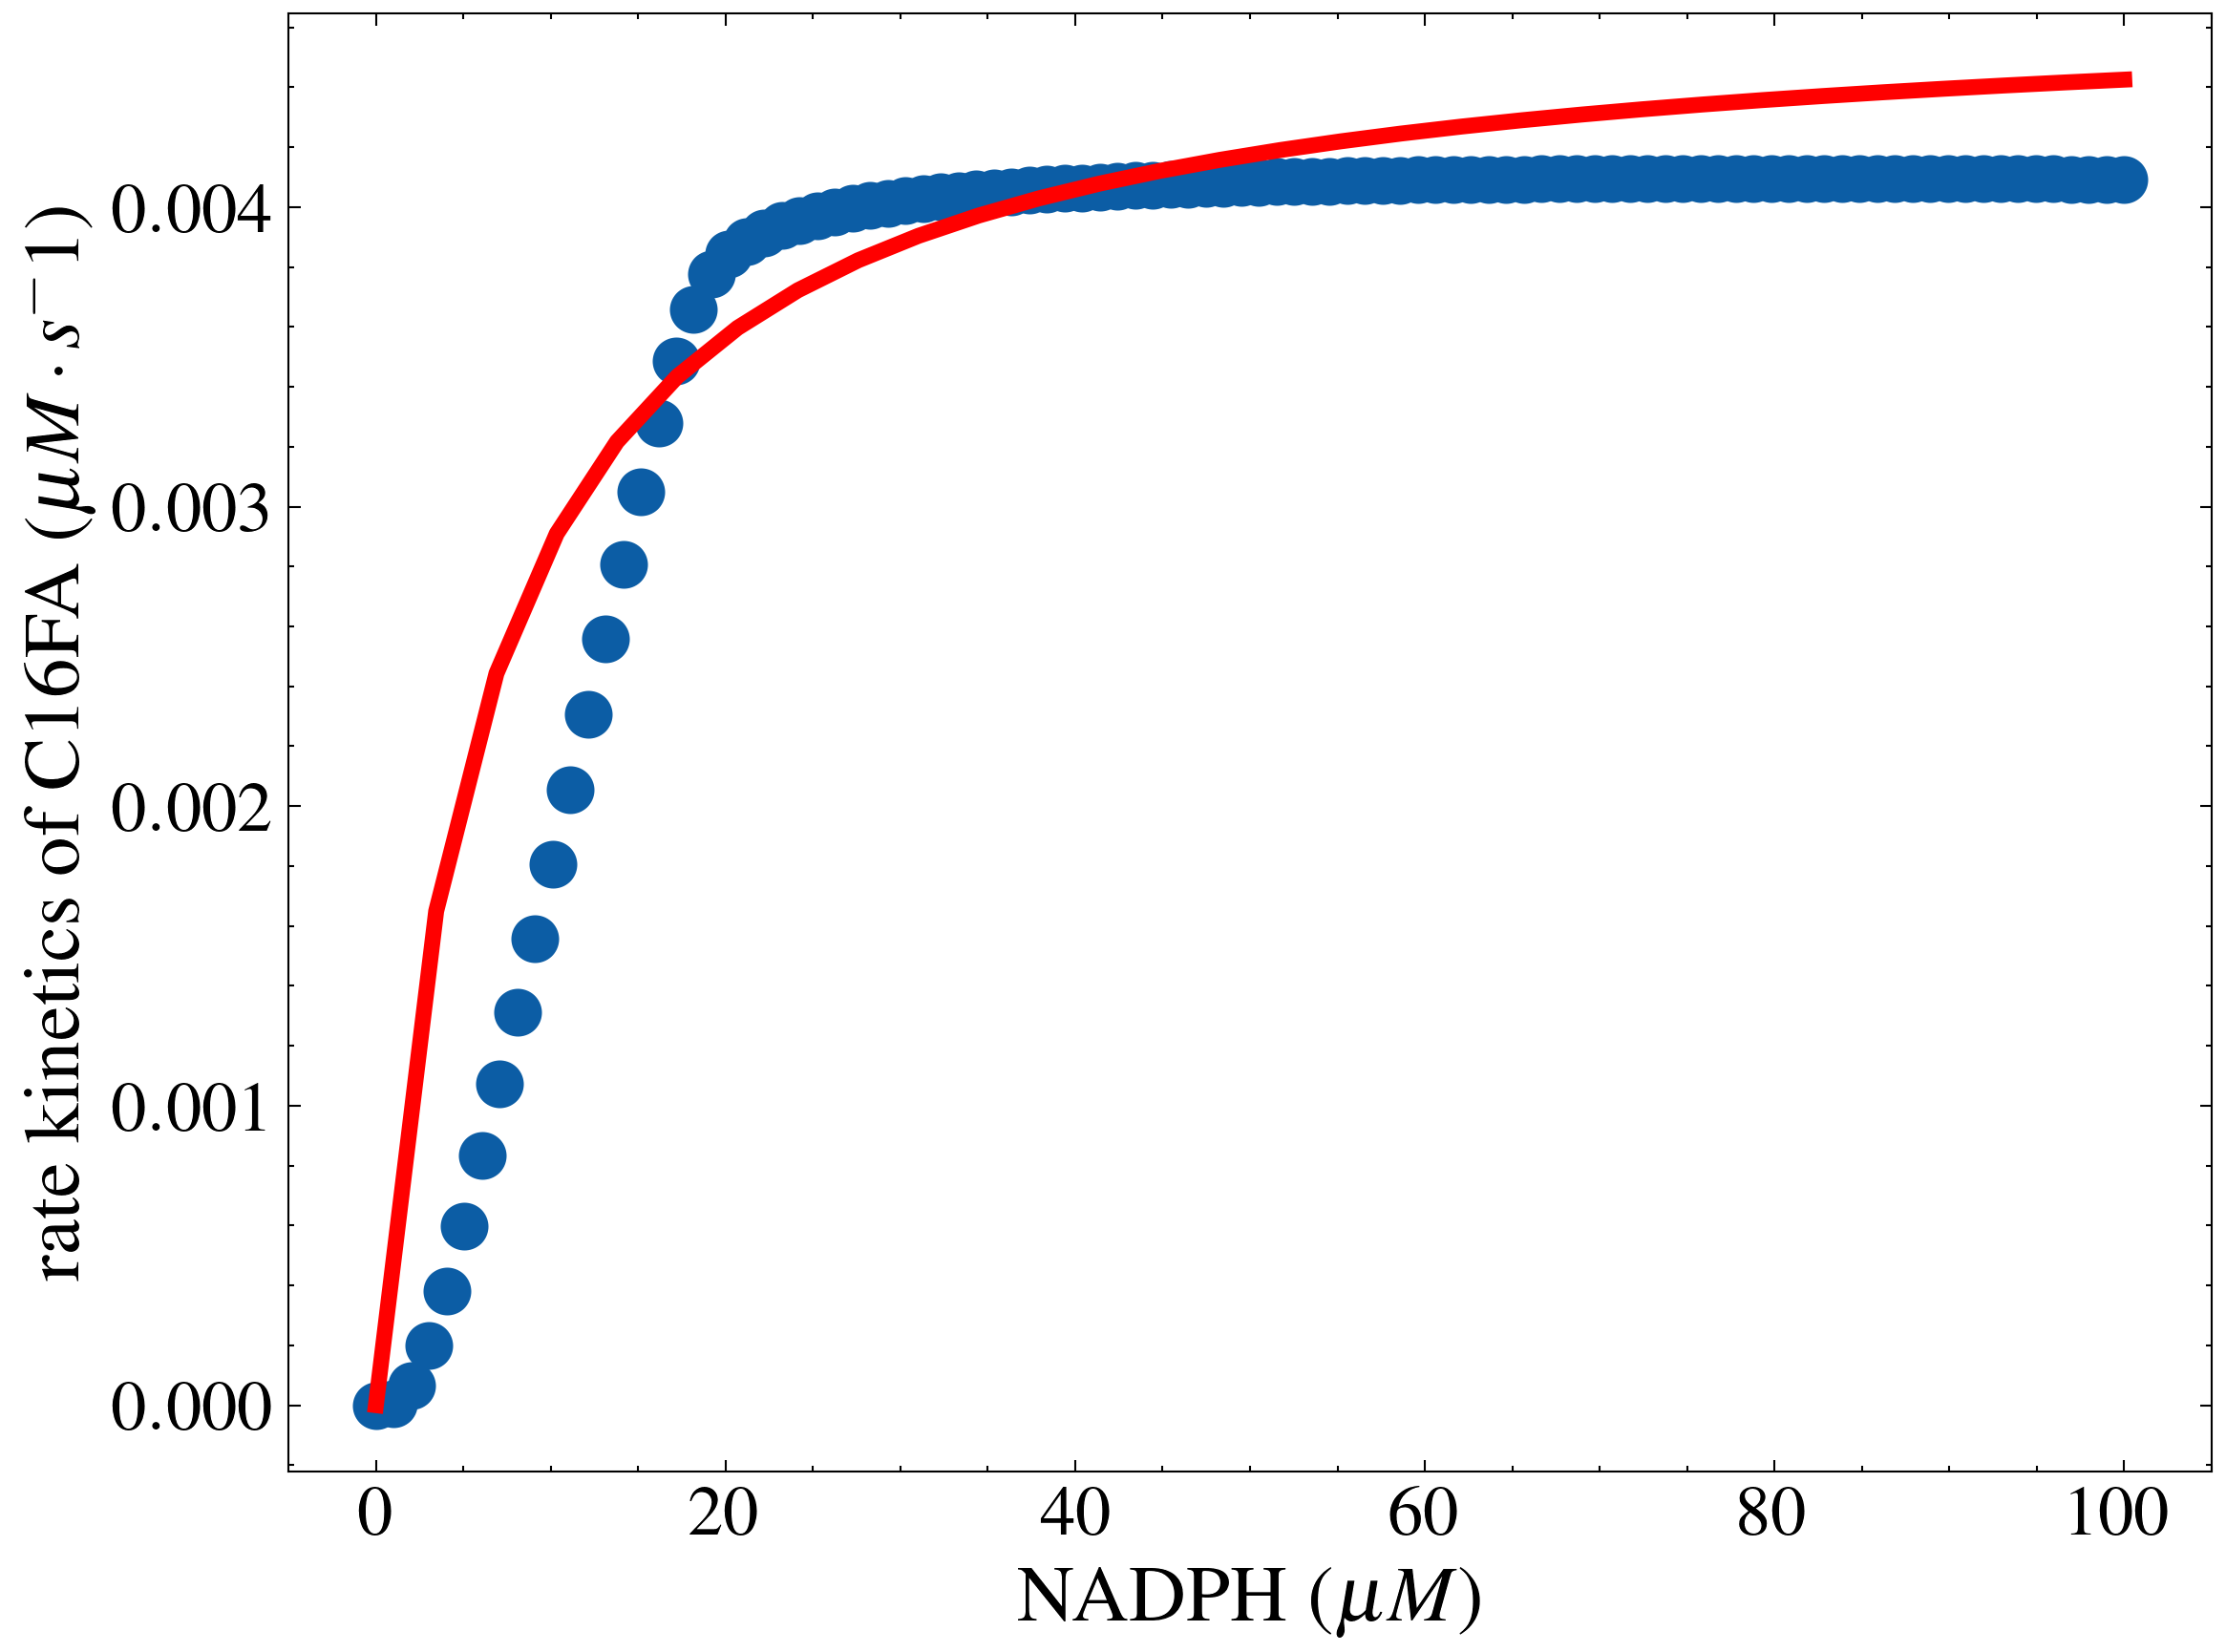

In [ ]:
plot_nadph =steady_state_kinetic_plot(
    "NADPH",
    "C16FA",
    compounds,
    system,
    y1_dict,
    param,
    0,
    100,
    100,
    max_timea,
    ncp_lista,
)
plt.plot(nadph, michealis_fitting(nadph, par_nadph_C16),color ="r", linewidth =4)
plt.savefig(RESULTS_DIR /"nadph_c16.eps", bbox_inches="tight")
plt.show()

In [ ]:
y1_dict

{'AcetylCoA': 108,
 'MalonylCoA': 22.04,
 'C14FA': 0.0,
 'C16FA': 0.0,
 'C18FA': 0.0,
 'CoA': 0.0,
 'E': 0.153,
 'EC2': 0.0,
 'EC4': 0.0,
 'EC6': 0.0,
 'EC8': 0.0,
 'EC10': 0.0,
 'EC12': 0.0,
 'EC14': 0.0,
 'EC16': 0.0,
 'EC18': 0.0,
 'ECoA': 0.0,
 'NADPH': 200}

## compare the  model to Cox and Hammes model

In [ ]:
def residual_cox(parameters, y, data):
    # y0[1] = parameters["y0_mal"].value
    # print(y0)
    model =cox_hammes_without_inhib(par=parameters,y=y)
    
    res = (model - data).ravel()

    return res





In [ ]:
par_cox =Parameters()
par_cox.add("E0", value=0.153, vary =False)
par_cox.add("kcat", value=23, min =0)
par_cox.add("Km_acet", value=0.72, min =0)
par_cox.add("Km_mal", value=2.5, min =0)
par_cox.add("Km_naph", value=2.9, min =0)
par_cox.add("Ki_acet", value=5.4, min =0)
par_cox.add("Ki_mal", value=3.1, min =0)

In [ ]:

result_nadph = minimize(
        residual_cox,
        params=par_cox, 
        args=(
        
            nadph,
        data_nadph,
        ),
        method="leastsq",
    )


TypeError: cox_hammes_without_inhib() got an unexpected keyword argument 'y'